# SUNSHIELD — BiLSTM Notebook 2: BiLSTM Training & Prediction

**Place in Dr. Mai's workflow:** the **"Training (BiLSTM) → gives predicted line"** box. Same work as LSTM
Notebook 2, with the BiLSTM in place of the LSTM and the window size already chosen by BiLSTM Notebook 1.

```
BiLSTM Notebook 1 (windows) → [ Training (BiLSTM) → predicted line ] → Anomaly definition (k) → F1 → best k
                                 (this notebook)                          (BiLSTM Notebook 3)     (BiLSTM Notebook 4)
```

| Step | What happens | Output |
|---|---|---|
| 1 | Build the BiLSTM (architecture from the checklist) | `model.summary()` |
| 2 | Train on ALL training data (faults included); validation for early stopping | training log |
| 3 | Plot training vs validation loss and mark the best epoch | `loss_curve.png` |
| 4 | Predict `AC_POWER` for train / validation / test and convert back to kW | `prediction_train/val/test.csv` |
| 5 | RMSE and MAE (kW) for each split, compared with the LSTM | metrics table (BiLSTM vs LSTM) |
| 6 | File 1: Training Prediction (actual + predicted kW) | `1_BiLSTM_Training_Output_Prediction.csv` |
| 7 | File 3: Validation Prediction | `3_BiLSTM_Validation_Output_Prediction.csv` |
| 8 | File 5: Testing Prediction | `5_BiLSTM_Testing_Output_Prediction.csv` |
| 9 | Save and zip outputs | `bilstm_step2_outputs.zip` |

**Same settings as the LSTM** (seed 42, Adam 0.001, MSE loss, batch 256, early stopping patience 10,
`TARGET_SHIFT = 0`), so the only difference between the models is the network itself.

## Settings

In [1]:
import os, shutil, glob, joblib
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow C++ log messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

MODEL_NAME = 'BiLSTM'
SEED = 42
EPOCHS = 100            # upper limit; early stopping usually stops much earlier
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
PATIENCE = 10           # stop after 10 epochs without a better validation loss

# Same seed + deterministic operations = the same result every time the notebook runs
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

SPLITS = ['train', 'val', 'test']
SPLIT_NAMES = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
OUT_DIR = 'bilstm_step2_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style (light surface, recessive grid, 2 px lines)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

I0000 00:00:1793927075.953466    1152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793927075.954076    1152 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793927077.291877    1152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793927077.292303    1152 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | GPU: False


## Upload the inputs

Run the cell below, click **Choose Files** and select **all 3 files together** (hold Ctrl, or Cmd on a Mac):

| File | From | Used for |
|---|---|---|
| `bilstm_step1_outputs.zip` | BiLSTM Notebook 1 | the windows (X, y) and their readings (meta) |
| `step1_outputs.zip` | LSTM Notebook 1 | `scalers.pkl`, to convert predictions back to kW |
| `step2_outputs.zip` | LSTM Notebook 2 | the LSTM results, for the comparison in Step 5 |

In [2]:
from google.colab import files
uploaded = files.upload()
for name in uploaded:
    if name.lower().startswith('bilstm'):
        folder = 'bilstm_step1_outputs'
    elif 'step2' in name:
        folder = 'lstm_step2_outputs'
    else:
        folder = 'step1_outputs'
    shutil.unpack_archive(name, folder, 'zip')
    print(f'{name} → {folder}/')

bilstm_step1_outputs.zip → bilstm_step1_outputs/


step1_outputs.zip → step1_outputs/
step2_outputs.zip → lstm_step2_outputs/


## Load the windows from BiLSTM Notebook 1

The window size is read from the file names (`X_train_w<W>.npy`), so it is always the size BiLSTM
Notebook 1 chose. The check at the end makes sure `y` turns back into the same kW values as the `AC_POWER`
column of the meta file: the windows and the scaler belong together.

In [3]:
STEP1_DIR = 'bilstm_step1_outputs'
W = int(glob.glob(f'{STEP1_DIR}/X_train_w*.npy')[0].split('_w')[-1].split('.')[0])

data = {}
for s in SPLITS:
    X = np.load(f'{STEP1_DIR}/X_{s}_w{W}.npy')
    y = np.load(f'{STEP1_DIR}/y_{s}_w{W}.npy')
    meta = pd.read_csv(f'{STEP1_DIR}/meta_{s}_w{W}.csv', parse_dates=['DATE_TIME'])
    data[s] = (X, y, meta)
    print(f'{s:5s}: X {X.shape}  y {y.shape}  targets from {meta.DATE_TIME.min()} to {meta.DATE_TIME.max()}')

target_scaler = joblib.load('step1_outputs/scalers.pkl')['target']
KW_PER_Z = target_scaler.scale_[0]      # 1 scaled unit of AC_POWER = this many kW

for s in SPLITS:
    X, y, meta = data[s]
    assert not np.isnan(X).any() and not np.isnan(y).any()
    assert np.allclose(target_scaler.inverse_transform(y[:, None]).ravel(), meta['AC_POWER'], atol=1e-2)
print(f'\nWindow size W = {W} ({W * 15 / 60:g} h) | 1 scaled unit = {KW_PER_Z:.1f} kW | y matches the kW values.')
print(open(f'{STEP1_DIR}/window_justification.txt').read())

train: X (41937, 32, 3)  y (41937,)  targets from 2020-05-15 13:30:00 to 2020-06-07 19:00:00
val  : X (11968, 32, 3)  y (11968,)  targets from 2020-06-08 05:45:00 to 2020-06-12 18:45:00
test : X (11110, 32, 3)  y (11110,)  targets from 2020-06-13 05:45:00 to 2020-06-17 18:45:00



Window size W = 32 (8 h) | 1 scaled unit = 405.0 kW | y matches the kW values.
BiLSTM: window size 32 (8 h) was selected because it gave the lowest validation loss (MSE 0.1857, RMSE 174.5 kW) among [8, 16, 24, 32, 48], 1.56% lower than the next best (W = 24).



/home/user/SUNSHIELD/.venv/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## Step 1 — Build the BiLSTM

```
Input (W readings × 3 weather features)
  → Bidirectional(LSTM(64))  one LSTM reads the window forwards, one backwards → 128 values per step
  → Dropout(0.2)
  → Bidirectional(LSTM(32))  last state of both directions → 64 values
  → Dropout(0.2)
  → Dense(1)  = predicted AC_POWER (scaled)
```

Both directions only read readings **inside the window**, and the window ends at the reading being
predicted, so the backward LSTM never sees a later reading.
Weights (each direction is a full LSTM with 4 gates):
- Bidirectional(LSTM(64)) on 3 inputs: 2 × 4 × (64 × (3 + 64) + 64) = **34,816**
- Bidirectional(LSTM(32)) on 128 inputs: 2 × 4 × (32 × (128 + 32) + 32) = **41,216**
- Dense(1) on 64 inputs: 64 + 1 = **65** → total **76,097**

Loss = MSE, optimizer = Adam, exactly like the LSTM.

In [4]:
def build_model(window, n_features=3):
    model = keras.Sequential([
        keras.Input(shape=(window, n_features)),
        layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
        layers.Dropout(0.2),
        layers.Bidirectional(layers.LSTM(32)),
        layers.Dropout(0.2),
        layers.Dense(1),
    ], name=f'bilstm_window_{window}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse')
    return model

keras.utils.set_random_seed(SEED)
model = build_model(W)
model.summary()

with open(os.path.join(OUT_DIR, 'model_summary.txt'), 'w') as f:
    model.summary(print_fn=lambda line, **kwargs: f.write(line + '\n'))

Model: "bilstm_window_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 32, 128)        │        34,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,097 (297.25 KB)

 Trainable params: 76,097 (297.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 2 — Train on ALL training data (faults included); validation for early stopping

Nothing is removed from the training windows, as in the LSTM: daytime readings with zero power
(possible faults) stay in. Validation only decides **when to stop**: training stops after `PATIENCE`
epochs without a better validation loss, and the best epoch's weights are restored.
Every epoch is written to `training_log.csv`.

In [5]:
X_tr, y_tr, meta_tr = data['train']
X_va, y_va, _ = data['val']
print(f'Training windows: {len(y_tr):,} — of which {(meta_tr["AC_POWER"] == 0).sum():,} have AC_POWER = 0 '
      f'during the day (kept in training)\n')

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=BATCH_SIZE,
                    shuffle=True, verbose=2,
                    callbacks=[early_stop, keras.callbacks.CSVLogger(os.path.join(OUT_DIR, 'training_log.csv'))]
                    ).history
model.save(os.path.join(OUT_DIR, 'bilstm_model.keras'))

best_epoch = int(np.argmin(history['val_loss']))
nb1 = pd.read_csv(f'{STEP1_DIR}/window_size_experiment.csv', index_col=0)
print(f'\nStopped after {len(history["val_loss"])} epochs; best epoch = {best_epoch + 1} '
      f'(val loss {history["val_loss"][best_epoch]:.4f}).')
print(f'Notebook 1 got val loss {nb1.loc[W, "val loss (MSE, scaled)"]:.4f} for W = {W} with the same settings '
      f'(a small difference is normal when one ran on GPU and the other on CPU).')

Training windows: 41,937 — of which 4,806 have AC_POWER = 0 during the day (kept in training)



Epoch 1/100


164/164 - 15s - 90ms/step - loss: 0.4562 - val_loss: 0.2348


Epoch 2/100


164/164 - 10s - 60ms/step - loss: 0.3837 - val_loss: 0.2058


Epoch 3/100


... (48 outputs left out)

164/164 - 10s - 64ms/step - loss: 0.3174 - val_loss: 0.1899


Epoch 28/100


164/164 - 10s - 60ms/step - loss: 0.3146 - val_loss: 0.1937



Stopped after 28 epochs; best epoch = 18 (val loss 0.1854).
Notebook 1 got val loss 0.1857 for W = 32 with the same settings (a small difference is normal when one ran on GPU and the other on CPU).


## Step 3 — Training vs validation loss, best epoch marked

- both curves going down = the model is learning
- validation curve turning up while training keeps going down = overfitting → early stopping prevents it
- training loss is measured **with** dropout on, validation loss **without** it, and the training days
  contain more faults, so the training curve can sit above the validation curve

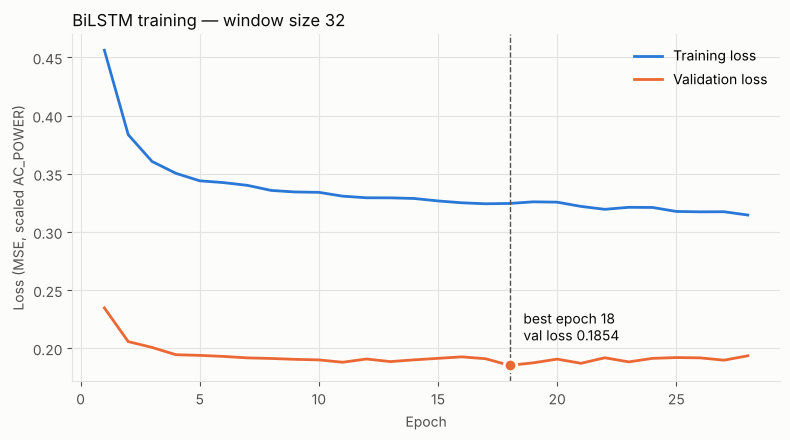

In [6]:
epochs = np.arange(1, len(history['loss']) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs, history['loss'], color=BLUE, label='Training loss')
ax.plot(epochs, history['val_loss'], color=ORANGE, label='Validation loss')
ax.axvline(best_epoch + 1, color=INK_2, linestyle='--', linewidth=1)
ax.plot(best_epoch + 1, history['val_loss'][best_epoch], 'o', color=ORANGE, markersize=9,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f'best epoch {best_epoch + 1}\nval loss {history["val_loss"][best_epoch]:.4f}',
            (best_epoch + 1, history['val_loss'][best_epoch]), textcoords='offset points',
            xytext=(10, 18), color=INK)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE, scaled AC_POWER)')
ax.set_title(f'{MODEL_NAME} training — window size {W}', loc='left')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'loss_curve.png'), dpi=150)
plt.show()

## Step 4 — Predict `AC_POWER` for train / validation / test and convert back to kW

$x = z \cdot \sigma + \mu$ with $\mu$, $\sigma$ from the LSTM training data (`scalers.pkl`), so all models are
converted with the same numbers. The columns are the same as the LSTM files, so Notebook 3 can read them
without any change.

In [7]:
predictions = {}
for split in SPLITS:
    X, y, meta = data[split]
    pred_z = model.predict(X, batch_size=2048, verbose=0).ravel()
    out = meta.rename(columns={'AC_POWER': 'ACTUAL_AC_POWER_kW'})
    out['PREDICTED_AC_POWER_kW'] = target_scaler.inverse_transform(pred_z[:, None]).ravel()
    out = out.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
    out.to_csv(os.path.join(OUT_DIR, f'prediction_{split}.csv'), index=False)
    predictions[split] = out
    print(f'{split:5s}: {len(out):,} predictions | predicted range {out.PREDICTED_AC_POWER_kW.min():.1f} '
          f'to {out.PREDICTED_AC_POWER_kW.max():.1f} kW | negative predictions: '
          f'{(out.PREDICTED_AC_POWER_kW < 0).sum()}')

predictions['test'].head()

train: 41,937 predictions | predicted range -23.8 to 1256.9 kW | negative predictions: 1560


val  : 11,968 predictions | predicted range -9.1 to 1309.4 kW | negative predictions: 462


test : 11,110 predictions | predicted range -9.7 to 1284.1 kW | negative predictions: 220


,PLANT_ID,SOURCE_KEY,DATE_TIME,ACTUAL_AC_POWER_kW,PREDICTED_AC_POWER_kW
0,4135001,1BY6WEcLGh8j5v7,2020-06-13 05:45:00,0.000000,6.398285
1,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:00:00,9.162500,16.761902
2,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:15:00,33.228571,36.790619
3,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:30:00,55.037500,59.196228
4,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:45:00,102.142857,97.034546


## Step 5 — RMSE and MAE (kW) for each split, compared with the LSTM

$\text{RMSE} = \sqrt{\frac{1}{n}\sum (y - \hat y)^2}$ punishes big errors more;
$\text{MAE} = \frac{1}{n}\sum |y - \hat y|$ is the average error in kW.

Two comparisons:
- **Each model on its own predictions** — the numbers each model reports.
- **Same readings only** — the BiLSTM and the LSTM can use different window sizes, so the first readings of
  each stretch may be predicted by one model and not the other. Here both are scored on exactly the readings
  they both predicted. Validation is the same set either way (every window size predicts all validation readings).

A negative difference = the BiLSTM has the smaller error.

In [8]:
KEYS = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']

def error_metrics(actual, predicted):
    err = actual - predicted
    rmse = np.sqrt((err ** 2).mean())
    return {'readings': len(err), 'RMSE (kW)': rmse, 'MAE (kW)': err.abs().mean(),
             'RMSE % of range': 100 * rmse / (actual.max() - actual.min())}

metrics = pd.DataFrame({s: error_metrics(predictions[s]['ACTUAL_AC_POWER_kW'],
                                         predictions[s]['PREDICTED_AC_POWER_kW']) for s in SPLITS}).T
metrics.index.name = 'split'
metrics.to_csv(os.path.join(OUT_DIR, 'metrics.csv'))

lstm_metrics = pd.read_csv('lstm_step2_outputs/metrics.csv', index_col='split')
own = pd.DataFrame({
    f'{MODEL_NAME} RMSE (kW)': metrics['RMSE (kW)'], 'LSTM RMSE (kW)': lstm_metrics['RMSE (kW)'],
    'RMSE difference (kW)': metrics['RMSE (kW)'] - lstm_metrics['RMSE (kW)'],
    f'{MODEL_NAME} MAE (kW)': metrics['MAE (kW)'], 'LSTM MAE (kW)': lstm_metrics['MAE (kW)'],
    'MAE difference (kW)': metrics['MAE (kW)'] - lstm_metrics['MAE (kW)'],
    f'{MODEL_NAME} readings': metrics['readings'].astype(int), 'LSTM readings': lstm_metrics['readings'].astype(int)})
print(f'{MODEL_NAME} vs LSTM — each model on its own predictions:')
display(own.round(2))

rows = {}
for s in SPLITS:
    lstm_pred = pd.read_csv(f'lstm_step2_outputs/prediction_{s}.csv', parse_dates=['DATE_TIME'])
    both = predictions[s].merge(lstm_pred[KEYS + ['PREDICTED_AC_POWER_kW']], on=KEYS, suffixes=('', '_LSTM'))
    mine = error_metrics(both['ACTUAL_AC_POWER_kW'], both['PREDICTED_AC_POWER_kW'])
    lstm = error_metrics(both['ACTUAL_AC_POWER_kW'], both['PREDICTED_AC_POWER_kW_LSTM'])
    rows[s] = {'same readings': mine['readings'],
               f'{MODEL_NAME} RMSE (kW)': mine['RMSE (kW)'], 'LSTM RMSE (kW)': lstm['RMSE (kW)'],
               'RMSE difference (kW)': mine['RMSE (kW)'] - lstm['RMSE (kW)'],
               f'{MODEL_NAME} MAE (kW)': mine['MAE (kW)'], 'LSTM MAE (kW)': lstm['MAE (kW)'],
               'MAE difference (kW)': mine['MAE (kW)'] - lstm['MAE (kW)']}
same = pd.DataFrame(rows).T
same.index.name = 'split'
same['same readings'] = same['same readings'].astype(int)

comparison = pd.concat({'own predictions': own, 'same readings': same})
comparison.to_csv(os.path.join(OUT_DIR, f'metrics_{MODEL_NAME.lower()}_vs_lstm.csv'))
print(f'{MODEL_NAME} vs LSTM — on the same readings only:')
same.round(2)

BiLSTM vs LSTM — each model on its own predictions:


,BiLSTM RMSE (kW),LSTM RMSE (kW),RMSE difference (kW),BiLSTM MAE (kW),LSTM MAE (kW),MAE difference (kW),BiLSTM readings,LSTM readings
split,,,,,,,,
train,228.71,232.67,-3.96,119.8,123.11,-3.31,41937,36491
val,174.40,177.16,-2.76,85.1,88.18,-3.08,11968,11968
test,190.08,190.86,-0.78,95.4,94.56,0.84,11110,10758


BiLSTM vs LSTM — on the same readings only:


,same readings,BiLSTM RMSE (kW),LSTM RMSE (kW),RMSE difference (kW),BiLSTM MAE (kW),LSTM MAE (kW),MAE difference (kW)
split,,,,,,,
train,36491,229.38,232.67,-3.29,119.67,123.11,-3.44
val,11968,174.40,177.16,-2.76,85.10,88.18,-3.08
test,10758,193.10,190.86,2.24,97.87,94.56,3.31


## Steps 6–8 — Files 1, 3 and 5

The three prediction files with the names from the checklist: inverter, time, actual kW and predicted kW.

In [9]:
final_files = {
    f'1_{MODEL_NAME}_Training_Output_Prediction.csv': predictions['train'],
    f'3_{MODEL_NAME}_Validation_Output_Prediction.csv': predictions['val'],
    f'5_{MODEL_NAME}_Testing_Output_Prediction.csv': predictions['test'],
}
for name, df in final_files.items():
    df.to_csv(os.path.join(OUT_DIR, name), index=False)
    print(f'{name:45s} {len(df):7,} rows  columns: {list(df.columns)}')

1_BiLSTM_Training_Output_Prediction.csv        41,937 rows  columns: ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']


3_BiLSTM_Validation_Output_Prediction.csv      11,968 rows  columns: ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']
5_BiLSTM_Testing_Output_Prediction.csv         11,110 rows  columns: ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', 'ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']


## Step 9 — Save and zip outputs

| File | Content | Used by |
|---|---|---|
| `model_summary.txt` | Step 1 architecture | report |
| `training_log.csv` | Step 2 loss per epoch | report |
| `bilstm_model.keras` | trained model | re-use without retraining |
| `loss_curve.png` | Step 3 plot | report |
| `prediction_train/val/test.csv` | actual + predicted kW per reading | **BiLSTM Notebook 3** |
| `metrics.csv` | Step 5 BiLSTM metrics | report |
| `metrics_bilstm_vs_lstm.csv` | Step 5 comparison with the LSTM | report |
| `1_…`, `3_…`, `5_BiLSTM_…_Output_Prediction.csv` | Files 1, 3, 5 | report |

In [10]:
shutil.make_archive('bilstm_step2_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:45s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('bilstm_step2_outputs.zip')    # keep this file: BiLSTM Notebook 3 needs it

1_BiLSTM_Training_Output_Prediction.csv         2.74 MB
3_BiLSTM_Validation_Output_Prediction.csv       0.78 MB
5_BiLSTM_Testing_Output_Prediction.csv          0.73 MB
bilstm_model.keras                              0.97 MB
loss_curve.png                                  0.07 MB
metrics.csv                                     0.00 MB
metrics_bilstm_vs_lstm.csv                      0.00 MB
model_summary.txt                               0.00 MB
prediction_test.csv                             0.73 MB
prediction_train.csv                            2.74 MB
prediction_val.csv                              0.78 MB
training_log.csv                                0.00 MB
